**See the correctness of the expert predicitions**

In [2]:
def predicition_results(team_id, results):
    ratio_list_1 = []
    dates_list = []
    date_count = 1
    for date, matches in results.items():
        correct, wrong = 0, 0
        for match in matches:
            if match[2] > match[6]:
                actual_winner = match[0]
            else:
                actual_winner = match[4]

            if match[8] == actual_winner:
                correct += 1
            else:
                wrong += 1
        ratio = correct / (correct + wrong)
        ratio_list_1.append(ratio)
        dates_list.append(date_count)
        date_count += 1

    # Calculate percentiles
    p25 = np.percentile(ratio_list_1, 25)
    p50 = np.percentile(ratio_list_1, 50)
    p75 = np.percentile(ratio_list_1, 75)

    # Plot the graph
    plt.plot(dates_list, ratio_list_1, label='Expert Prediction Accuracy')
    plt.axhline(p25, color='green', linestyle='--', label='25th Percentile')
    plt.axhline(p50, color='blue', linestyle='--', label='50th Percentile (Median)')
    plt.axhline(p75, color='red', linestyle='--', label='75th Percentile')
    plt.xlabel('Date Count')
    plt.ylabel('Accuracy Ratio')
    plt.title('Expert Prediction Results Over Time')
    plt.legend()
    plt.show()

    return ratio_list_1

**See the correctness of the sportsbook predicitions**

In [3]:
def sportbook_predictions(team_id, results):
    ratio_list_2 = []
    dates_list = []
    date_count = 1
    for date, matches in results.items():
        correct, wrong = 0, 0
        for match in matches:
            if match[2] > match[6]:
                actual_winner = match[0]
            else:
                actual_winner = match[4]

            if '-' in match[3]:
                predicted_winner = match[0]
            else:
                predicted_winner = match[4]

            if predicted_winner == actual_winner:
                correct += 1
            else:
                wrong += 1
        ratio = correct / (correct + wrong)
        ratio_list_2.append(ratio)
        dates_list.append(date_count)
        date_count += 1

    # Calculate percentiles
    p25 = np.percentile(ratio_list_2, 25)
    p50 = np.percentile(ratio_list_2, 50)
    p75 = np.percentile(ratio_list_2, 75)

    # Plot the graph
    plt.plot(dates_list, ratio_list_2, label='Sportsbook Prediction Accuracy')
    plt.axhline(p25, color='green', linestyle='--', label='25th Percentile')
    plt.axhline(p50, color='blue', linestyle='--', label='50th Percentile (Median)')
    plt.axhline(p75, color='red', linestyle='--', label='75th Percentile')
    plt.xlabel('Date Count')
    plt.ylabel('Accuracy Ratio')
    plt.title('Sportsbook Prediction Results Over Time')
    plt.legend()
    plt.show()

    return ratio_list_2

**See the correctness when sportsbook and predictions pick the same winner**

In [4]:
def sportsbook_expert_prediction(team_id, results):
    ratio_list_3 = []
    dates_list = []
    date_count = 1
    for date, matches in results.items():
        combined, correct, wrong = 0, 0, 0
        for match in matches:
            if match[2] > match[6]:
                actual_winner = match[0]
            else:
                actual_winner = match[4]

            if '-' in match[3]:
                predicted_winner_sportsbook = match[0]
            else:
                predicted_winner_sportsbook = match[4]

            if predicted_winner_sportsbook == match[8]:
                combined += 1

            if predicted_winner_sportsbook == match[8] == actual_winner:
                correct += 1
            else:
                wrong += 1

        try:
            ratio = correct / combined
        except ZeroDivisionError:
            ratio = 0
        ratio_list_3.append(ratio)
        dates_list.append(date_count)
        date_count += 1

    # Calculate percentiles
    p25 = np.percentile(ratio_list_3, 25)
    p50 = np.percentile(ratio_list_3, 50)
    p75 = np.percentile(ratio_list_3, 75)

    # Plot the graph
    plt.plot(dates_list, ratio_list_3, label='Sportsbook + Expert Prediction Accuracy')
    plt.axhline(p25, color='green', linestyle='--', label='25th Percentile')
    plt.axhline(p50, color='blue', linestyle='--', label='50th Percentile (Median)')
    plt.axhline(p75, color='red', linestyle='--', label='75th Percentile')
    plt.xlabel('Date Count')
    plt.ylabel('Accuracy Ratio')
    plt.title('Sportsbook + Expert Prediction Results Over Time')
    plt.legend()
    plt.show()

    return ratio_list_3

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = '../data/ncaa_box_scores_2024_25/scraped_ncaa_scores.csv'
data = pd.read_csv(file_path)
data = data.fillna('skip')

extracted_data = data[['Date', 'Team_1_id', 'Team_1_name', 'Team_1_score', 'Team_1_spread', 'Team_2_id', 'Team_2_name', 'Team_2_score','Team_2_spread', 'Predicted_winner_id','Predicted_winner_name']]

unique_dates = extracted_data['Date'].unique()

# Initialize a dictionary to store the results
results = {}

# Iterate through each unique date
for date in unique_dates:
    filtered_data = extracted_data[extracted_data['Date'] == date]
    matches = list(zip(filtered_data['Team_1_id'], filtered_data['Team_1_name'], filtered_data['Team_1_score'],
                    filtered_data['Team_1_spread'],filtered_data['Team_2_id'], filtered_data['Team_2_name'], filtered_data['Team_2_score'], filtered_data['Team_2_spread'],
                       filtered_data['Predicted_winner_id'], filtered_data['Predicted_winner_name']))
    results[date] = matches
print(f'match[0]: Team_1_id\nmatch[1]: Team_1_name\nmatch[2]: Team_1_score\nmatch[3]: Team_1_spread\nmatch[4]: Team_2_id\nmatch[5]: Team_2_name\nmatch[6]: Team_2_score\nmatch[7]: Team_2_spread\nmatch[8]: Predicted_winner_id\nmatch[9]: Predicted_winner_name\n')

match[0]: Team_1_id
match[1]: Team_1_name
match[2]: Team_1_score
match[3]: Team_1_spread
match[4]: Team_2_id
match[5]: Team_2_name
match[6]: Team_2_score
match[7]: Team_2_spread
match[8]: Predicted_winner_id
match[9]: Predicted_winner_name



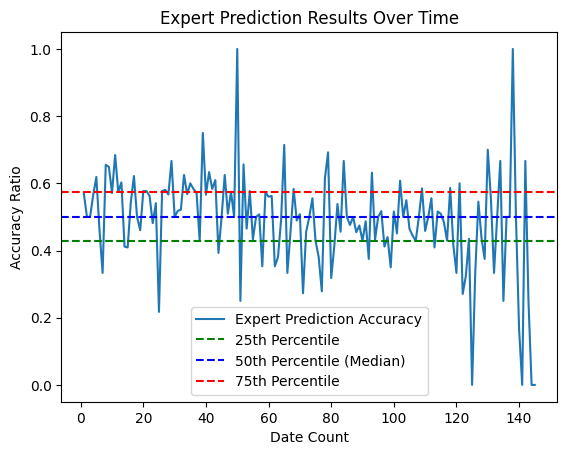

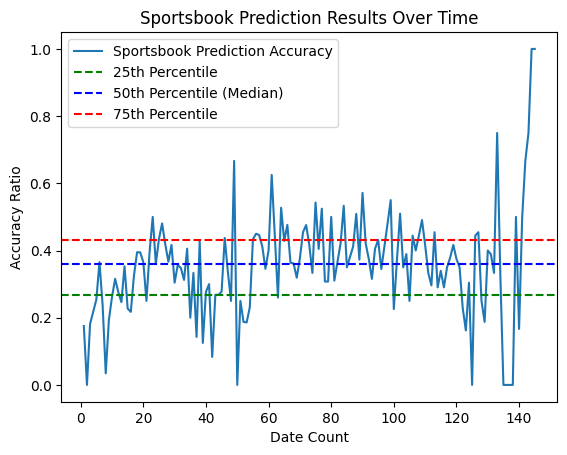

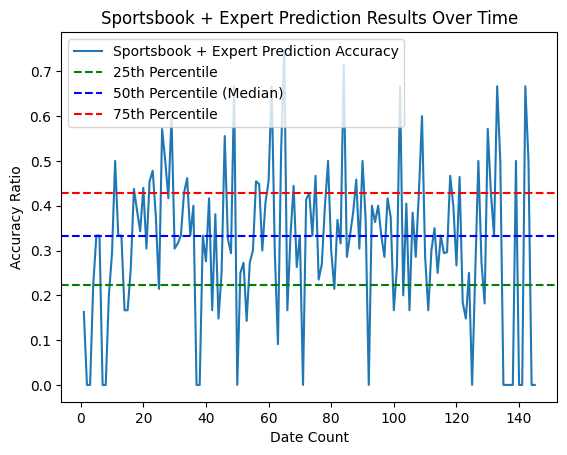

Average accuracy ratio for predicition_results: 0.49
Average accuracy ratio for sportbook_predictions: 0.36
Average accuracy ratio for sportsbook_expert_prediction: 0.32


In [13]:
import numpy as np

ratios_1 = predicition_results(None, results)
ratios_2 = sportbook_predictions(None, results)
ratios_3 = sportsbook_expert_prediction(None, results)

average_1 = np.mean(ratios_1)
average_2 = np.mean(ratios_2)
average_3 = np.mean(ratios_3)

print(f"Average accuracy ratio for predicition_results: {average_1:.2f}")
print(f"Average accuracy ratio for sportbook_predictions: {average_2:.2f}")
print(f"Average accuracy ratio for sportsbook_expert_prediction: {average_3:.2f}")